# C1 – Optimiseurs : SGD, Momentum, Adam
Implémentations dans `src/optimizers.py`, boucle d'entraînement dans `src/train.py`.

Les optimiseurs travaillent sur le vecteur plat $\theta$ avec l'interface `theta_new = opt.step(theta, grad)` :

- **SGD** : $\theta_{k+1}=\theta_k-\alpha g_k$
- **Momentum** : $v_{k+1}=\beta v_k+(1-\beta)g_k,\ \theta_{k+1}=\theta_k-\alpha v_{k+1}$
- **Adam** : $m_k=\beta_1m_{k-1}+(1-\beta_1)g_k,\ v_k=\beta_2v_{k-1}+(1-\beta_2)g_k^2,\ \hat m_k=\frac{m_k}{1-\beta_1^k},\ \hat v_k=\frac{v_k}{1-\beta_2^k},\ \theta_{k+1}=\theta_k-\alpha\frac{\hat m_k}{\sqrt{\hat v_k}+\varepsilon}$

À chaque époque, `train` enregistre (sur les jeux **entiers**, pas sur le mini-batch) : $F_{train}(\theta_k)$, $F_{val}(\theta_k)$, $\|\nabla F(\theta_k)\|$, accuracy train/val, et $\|\theta_k\|_2$ (poids seuls, utile pour les parties D et E).

In [1]:
%load_ext autoreload
%autoreload 2

import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_data
from src.model import MLP
from src.optimizers import SGD, Momentum, Adam
from src.train import train

SEED = 42
data = load_data(seed=SEED)

## 1. Vérification des formules sur un premier pas
On compare la sortie de chaque optimiseur à la formule calculée à la main.

In [2]:
theta = np.array([1.0, 2.0])
g = np.array([0.5, -1.0])

# SGD : theta - alpha g
assert np.allclose(SGD(lr=0.1).step(theta, g), theta - 0.1 * g)

# Momentum, 1er pas : v1 = (1 - beta) g  (v0 = 0)
assert np.allclose(Momentum(lr=0.1, beta=0.9).step(theta, g), theta - 0.1 * (0.1 * g))

# Adam, 1er pas : m_hat = g et v_hat = g^2  =>  theta - alpha * g / (|g| + eps) ~ theta - alpha * sign(g)
adam_step = Adam(lr=0.01).step(theta, g)
assert np.allclose(adam_step, theta - 0.01 * np.sign(g), atol=1e-6)
print("Les trois optimiseurs respectent les formules au premier pas.")

Les trois optimiseurs respectent les formules au premier pas.


## 2. Test sur une fonction quadratique mal conditionnée
$f(x)=\tfrac12 x^\top A x$ avec $A=\mathrm{diag}(1,50)$ : une direction « raide » et une « plate ». Le minimum est en 0, donc la norme de $x_k$ doit tendre vers 0.

SGD       ||x_300|| = 3.23e-04
Momentum  ||x_300|| = 3.94e-07
Adam      ||x_300|| = 6.05e-07


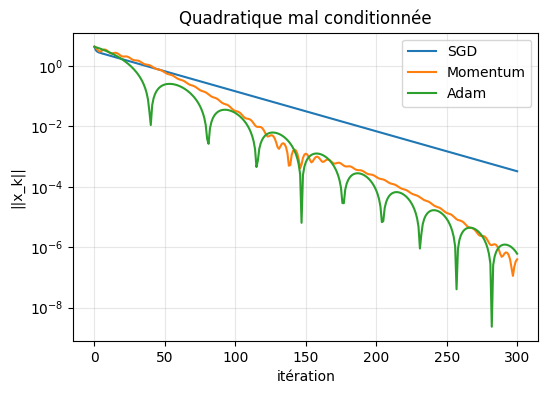

In [3]:
A = np.diag([1.0, 50.0])
configs = {"SGD": SGD(lr=0.03), "Momentum": Momentum(lr=0.03, beta=0.9), "Adam": Adam(lr=0.1)}

plt.figure(figsize=(6, 4))
for name, opt in configs.items():
    opt.reset(); x = np.array([3.0, 3.0]); dist = [np.linalg.norm(x)]
    for _ in range(300):
        x = opt.step(x, A @ x)               # gradient de f = A x
        dist.append(np.linalg.norm(x))
    print(f"{name:9s} ||x_300|| = {dist[-1]:.2e}")
    assert dist[-1] < 1e-2
    plt.semilogy(dist, label=name)
plt.xlabel("itération"); plt.ylabel("||x_k||"); plt.legend(); plt.grid(alpha=.3)
plt.title("Quadratique mal conditionnée"); plt.show()

## 3. Entraînement du réseau avec les trois optimiseurs
Protocole identique pour les trois (voir 6.4 du sujet) : même architecture, **même initialisation** (`MLP(seed=SEED)`), même split, même ordre des mini-batchs (`seed=0` dans `train`), même budget (100 époques, batch de 32). Seuls l'optimiseur et son learning rate changent.

Les learning rates ci-dessous sont un premier choix raisonnable ; leur étude systématique est faite en C2 (notebook 05).

In [4]:
EPOCHS, BATCH = 100, 32
runs = {
    "SGD":      SGD(lr=0.1),
    "Momentum": Momentum(lr=0.1, beta=0.9),
    "Adam":     Adam(lr=0.01),
}

histories = {}
for name, opt in runs.items():
    model = MLP(seed=SEED)                   # même initialisation pour tous
    histories[name] = train(model, opt, data, epochs=EPOCHS, batch_size=BATCH, seed=0)
    h = histories[name]
    print(f"{name:9s} loss_train={h['loss_train'][-1]:.4f} loss_val={h['loss_val'][-1]:.4f} "
          f"acc_val={h['acc_val'][-1]:.3f}")

SGD       loss_train=0.0806 loss_val=0.0858 acc_val=0.967
Momentum  loss_train=0.0813 loss_val=0.0861 acc_val=0.967
Adam      loss_train=0.0705 loss_val=0.0993 acc_val=0.960


## 4. Courbes

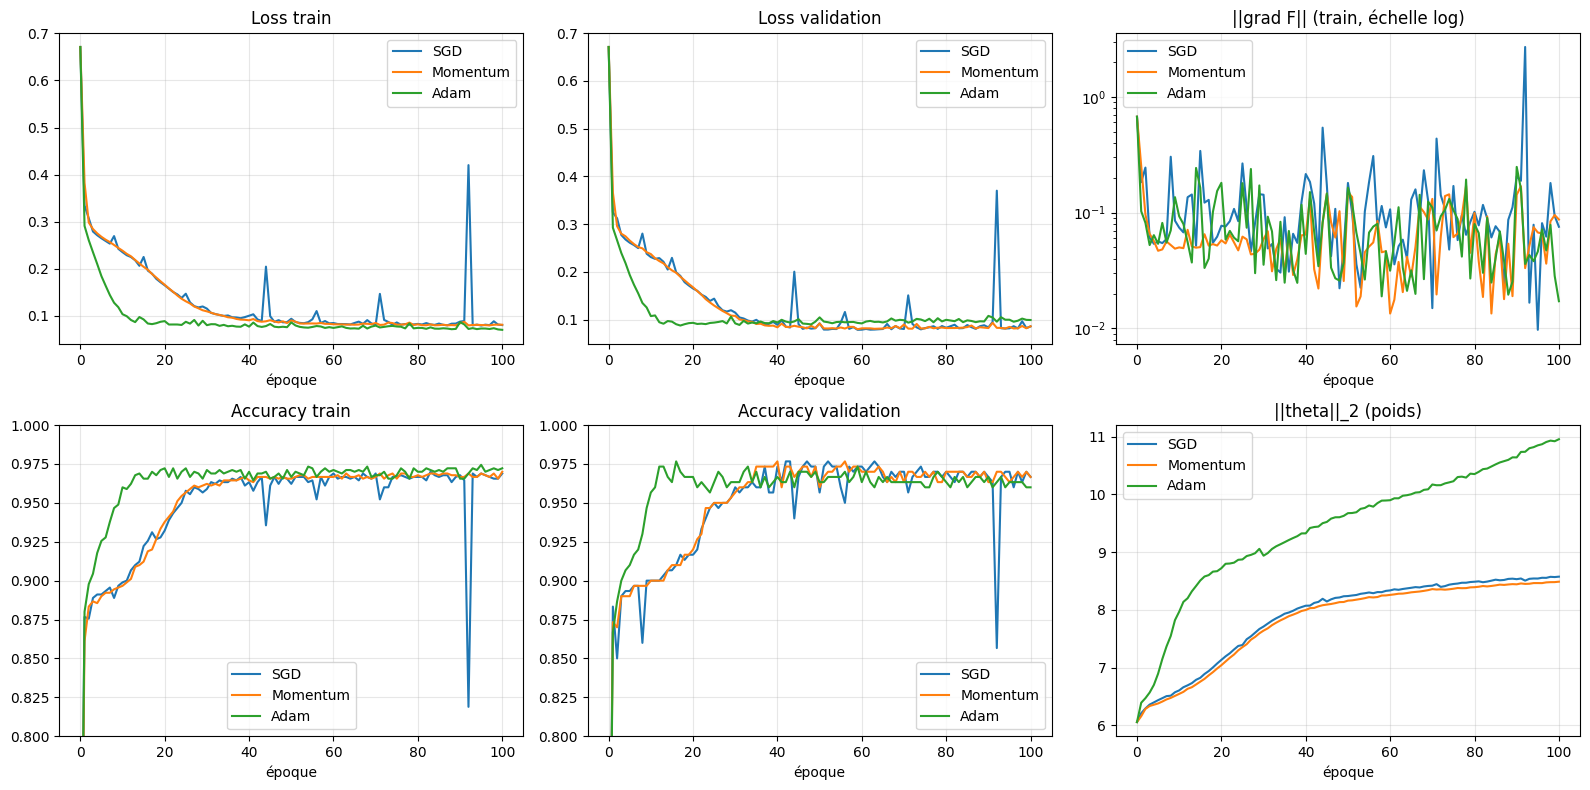

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
colors = {"SGD": "tab:blue", "Momentum": "tab:orange", "Adam": "tab:green"}

for name, h in histories.items():
    c = colors[name]
    ax[0, 0].plot(h["loss_train"], color=c, label=name)
    ax[0, 1].plot(h["loss_val"], color=c, label=name)
    ax[0, 2].semilogy(h["grad_norm"], color=c, label=name)
    ax[1, 0].plot(h["acc_train"], color=c, label=name)
    ax[1, 1].plot(h["acc_val"], color=c, label=name)
    ax[1, 2].plot(h["weight_norm"], color=c, label=name)

titles = ["Loss train", "Loss validation", "||grad F|| (train, échelle log)",
          "Accuracy train", "Accuracy validation", "||theta||_2 (poids)"]
for a, t in zip(ax.ravel(), titles):
    a.set_title(t); a.set_xlabel("époque"); a.grid(alpha=.3); a.legend()
ax[1, 0].set_ylim(0.8, 1.0); ax[1, 1].set_ylim(0.8, 1.0)
plt.tight_layout(); plt.show()

## 5. Tableau récapitulatif

In [6]:
def first_epoch_below(curve, thr):
    idx = np.where(np.array(curve) < thr)[0]
    return int(idx[0]) if len(idx) else None

rows = []
for name, h in histories.items():
    rows.append({
        "optimiseur": name,
        "loss train @ ép.10": h["loss_train"][10],
        "1re ép. loss<0.2": first_epoch_below(h["loss_train"], 0.2),
        "loss train finale": h["loss_train"][-1],
        "loss val finale": h["loss_val"][-1],
        "acc train": h["acc_train"][-1],
        "acc val": h["acc_val"][-1],
        "||grad|| final": h["grad_norm"][-1],
        "||theta|| final": h["weight_norm"][-1],
    })
pd.DataFrame(rows).set_index("optimiseur").round(4)

,loss train @ ép.10,1re ép. loss<0.2,loss train finale,loss val finale,acc train,acc val,||grad|| final,||theta|| final
optimiseur,,,,,,,,
SGD,0.2354,16,0.0806,0.0858,0.9689,0.9667,0.0754,8.5761
Momentum,0.2385,16,0.0813,0.0861,0.9700,0.9667,0.0871,8.4891
Adam,0.1037,5,0.0705,0.0993,0.9722,0.9600,0.0172,10.9560


## Bilan C1
- Les trois optimiseurs sont implémentés avec NumPy, sans autograd, et vérifiés sur des cas simples.
- Pour chaque optimiseur, on enregistre bien $F_{train}$, $F_{val}$, $\|\nabla F\|$, accuracy train/val (et $\|\theta\|_2$).
